# Tema 7. Ejercicio peatones en la pandemia

En este ejercicio vamos a utilizar incorporar gárficos al ejercicios de peatones hecho en el tema anterior.

Recuerda que trabajamos con el fichero .csv de la página del Portal de Datos Abiertos del Ayuntamiento de Madrid (https://datos.madrid.es/). Desde dicha página buscamos `peatones` y nos lleva a `Aforos de peatones y bicicletas` (https://datos.madrid.es/dataset/300321-0-aforos-peatones-bicicletas). Aquí tenemos que descargarnos el fichero csv de peatones correspondiente al año 2020
https://datos.madrid.es/dataset/300321-0-aforos-peatones-bicicletas/downloads.
 
 La descripción de cada campo del fichero es:

| Número de columna | Nombre columna            | Descripción                                                   | Valores esperados              |
|-------------------|---------------------------|---------------------------------------------------------------|--------------------------------|
| 1                 | fecha                     | Fecha del registro. Formato de fecha: DD-MM-AAAA.            |                                |
| 2                 | hora                      | Hora del registro. Formato de hora: HH:MM.                   |                                |
| 3                 | identificador             | Identificador único del registro.                             | Texto                          |
| 4                 | peatones                  | Número de peatones registrados.                             | Numérico                       |
| 5                 | device_id                 | Identificador único del registro.                             | Texto                          |
| 6                 | Número_distrito           | Número identificativo del distrito.                           | Numérico                       |
| 7                 | distrito                  | Nombre del distrito.                                          | Texto                          |
| 8                 | direccion                 | Dirección exacta del aforo.                                   | Texto                          |
| 9                 | observaciones_direccion   | Observaciones adicionales sobre la dirección del tráfico.     | Texto                          |
| 10                | latitude                  | Latitud geográfica del registro.                              | Número decimal (40.400000)     |
| 11                | longitude                 | Longitud geográfica del registro.                             | Número decimal (3.700000)      |



## Carga de datos y exploración del dataframe

Después de descargarnos el fichero `300321-3-aforos-peatones-bicicletas-csv.csv` correspondiente al año 2020  de la web https://datos.madrid.es/dataset/300321-0-aforos-peatones-bicicletas/downloads, lo dejamos en nuestra carpeta llamada Data y lo importamos como un dataframe llamado df.

Lo primero que tenemos que hacer es ver el contenido del fichero con una aplicación de texto plano y veo que el csv no está separado por `comas`, sino por `punto y coma` y además, utiliza la `coma` como separador decimal en LATITUD y LONGITUD. Así que se debe indicar `sep=";"` y `decimal=","` como parámetros de la carga de pandas `pd.read_csv`. 

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "./../Data/300321-3-aforos-peatones-bicicletas-csv.csv",
    sep=";",
    decimal=","
)

Muestra el DataFrame para comprobar que la carga se ha realizado correctamente. Puedes escribir simplemente el nombre del objeto.

In [40]:
df.shape

(166896, 12)

## Analizar y transformar los tipos de datos

Por el trabajo del tema anterior ya sabemos que 
- `PEATONES`, `NÚMERO_DISTRITO`, `NÚMERO`y `CÓDIGO_POSTAL` son `int64`,
- `LATITUD` y `LONGITUD` son `float64`.
- resto son de tipo  object

Pero en python tenemos un tipo de datos específico para la fecha y la hora

### Fechas 

En Python usamos `pd.to_datetime()` para convertir los tipos de los valores de la columna `FECHA`. con el parámetro `dayfirst = True` para indicar a pandas que, al interpretar una fecha, el primer número corresponde al día pues la fecha está escrita con el día antes del mes.

Al ejecutar `df["FECHA"] = pd.to_datetime(df["FECHA"], dayfirst=True)` da error porque el fichero hay dos formatos diferentes en las fechas, unos es con la hora `01/01/2020 00:00` y el otro es sin hora `02/09/2020`.
Pandas ha inferido inicialmente el formato `%d/%m/%Y %H:%M` pero ha detectado un valor que no seguía este formato. Pandas nos aconseja que tomemos el formato mixto para la fecha.

In [45]:
df["FECHA"] = pd.to_datetime(
    df["FECHA"],
    dayfirst = True,
    format = "mixed"
)

# comprobamos el tipo del primer valor de la columna `FECHA`
type(df["FECHA"].iloc[0])

pandas._libs.tslibs.timestamps.Timestamp

Ahora sí que estamos trabajando con fechas reales y podemos, por ejemplo, 
extraer de FECHA una parte concreta utilizando el accesor `.dt`. Prueba primero con el año (`df["FECHA"].dt.year`), después con el mes y finalmente con el nombre del día de la semana.

### Horas

Ahora vamos con la columna `HORA` que aparece como texto de la forma `00:00` y `01:00`. Estos valores podemos convertirlos a un tipo de hora con `pd.to_datetime()` con formato `%H:%M` como parámetro. Finalmente, aplicamos `pd.to_datetime().dt.time` para quedarnos únicamente con la parte de la hora.


In [48]:
df["HORA"] = pd.to_datetime(
    df["HORA"],
    format="%H:%M"
).dt.time

type(df["HORA"].iloc[0])

datetime.time

## Seleccionar ciertas columnas de la tabla, las que me interesan


Crea un nuevo DataFrame `df_1` seleccionando únicamente las columnas:
`FECHA`, `HORA`, `PEATONES`, `DISTRITO`, `NOMBRE_VIAL` y `NÚMERO`.
Para seleccionar varias columnas necesitas una lista de nombres dentro de los corchetes.
Usa `.copy()` para crear un nuevo DataFrame independiente.


In [50]:
df_1 = df[["FECHA", "HORA", "PEATONES", "DISTRITO", "NOMBRE_VIAL", "NÚMERO"]].copy()

## Cambiar el nombre de la columna `NOMBRE_VIAL`por `DIRECCIÓN`. 

Utiliza `rename()` para cambiar el nombre de `NOMBRE_VIAL` por `DIRECCIÓN`.
Después puedes consultar `df_1.columns` para comprobar el cambio.


In [52]:
df_1 = df_1.rename(columns={"NOMBRE_VIAL": "DIRECCIÓN"})
df_1.columns

Index(['FECHA', 'HORA', 'PEATONES', 'DISTRITO', 'DIRECCIÓN', 'NÚMERO'], dtype='object')

## Estudio de los peatones

`plt.plot()` dibuja un gráfico de líneas, el resultado puede parecer un gráfico de barras por dos motivos: hay muchos registros y puede haber varias observaciones con la misma fecha.

Text(0, 0.5, 'peatones')

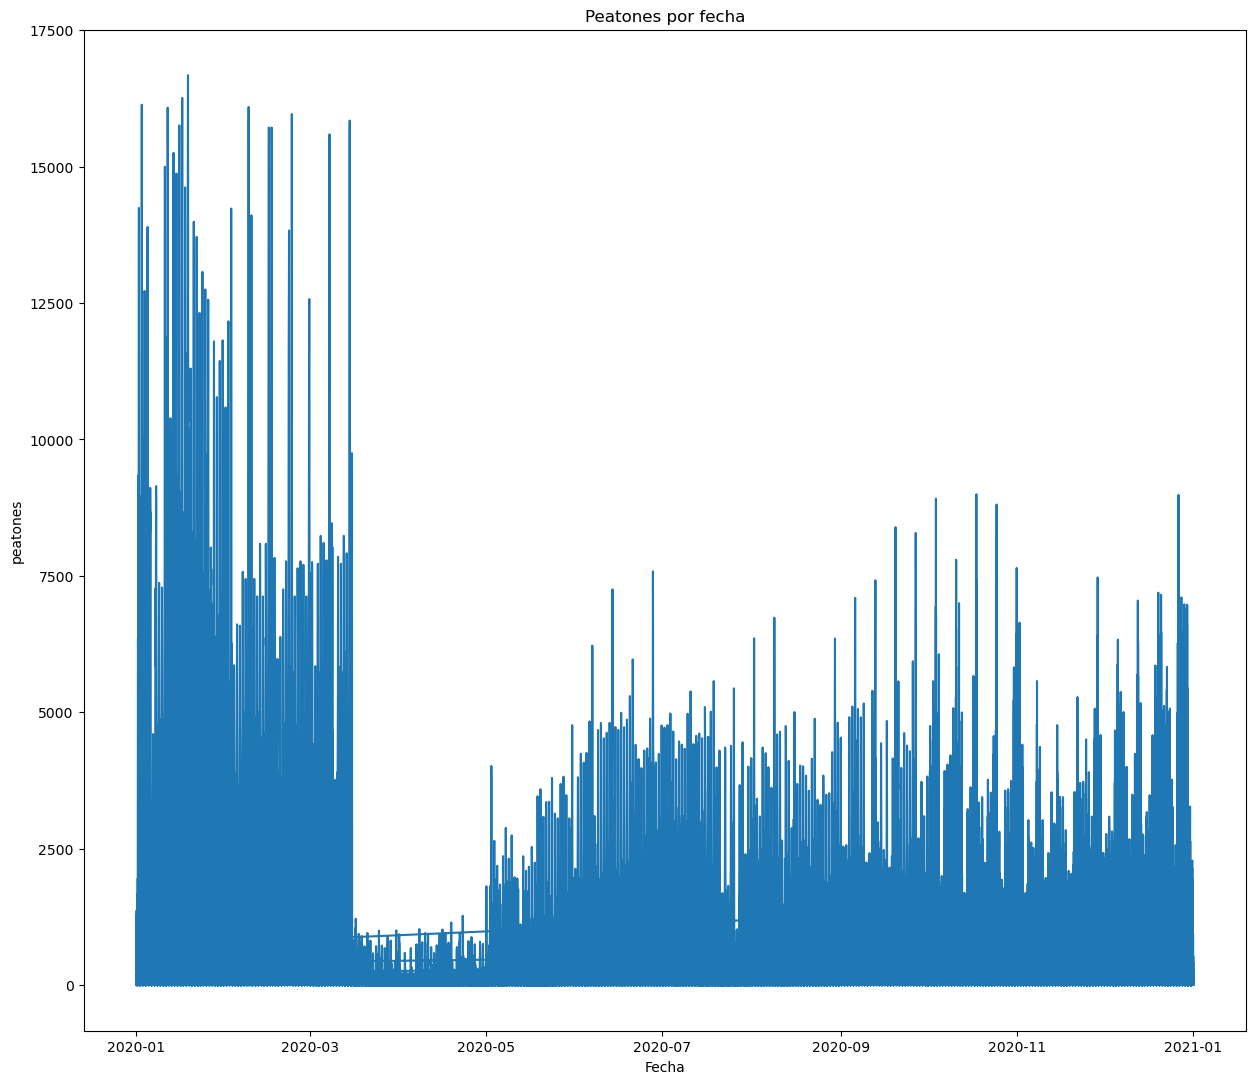

In [54]:
plt.figure(figsize=(15, 13))
plt.plot( df_1["FECHA"], df_1["PEATONES"])
plt.title("Peatones por fecha")
plt.xlabel("Fecha")
plt.ylabel("peatones")

¿Cómo representar el total de peatones por fecha?

(array([18262., 18322., 18383., 18444., 18506., 18567., 18628.]),
 [Text(18262.0, 0, '2020-01'),
  Text(18322.0, 0, '2020-03'),
  Text(18383.0, 0, '2020-05'),
  Text(18444.0, 0, '2020-07'),
  Text(18506.0, 0, '2020-09'),
  Text(18567.0, 0, '2020-11'),
  Text(18628.0, 0, '2021-01')])

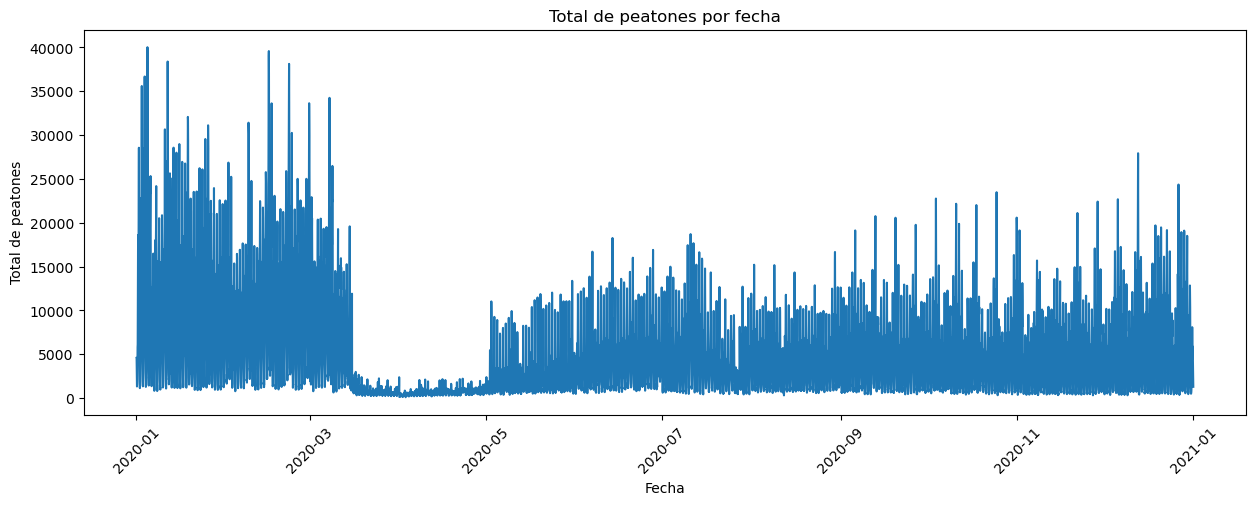

In [56]:
peatones_fecha = (
    df_1.groupby("FECHA")["PEATONES"]
    .sum()
    .sort_index()
)


plt.figure(figsize=(15, 5))

plt.plot(peatones_fecha.index, peatones_fecha.values)

plt.title("Total de peatones por fecha")
plt.xlabel("Fecha")
plt.ylabel("Total de peatones")

plt.xticks(rotation=45)



### Gráfico: distribución de los peatones

Cada valor de `PEATONES` es una observación del fichero. El *histograma* permite ver si la mayoría de las lecturas se concentran en valores pequeños o grandes. La distribución reúne distintas horas y puntos de aforo, por lo que no representa el total diario de la ciudad.

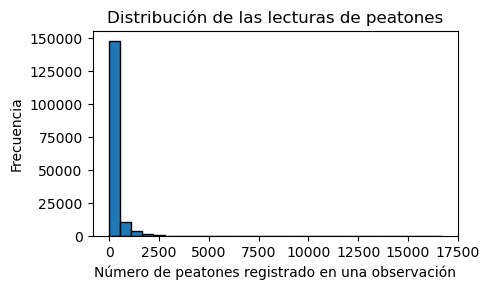

In [58]:
plt.figure(figsize=(5, 3))
plt.hist(df_1["PEATONES"], bins=30, edgecolor="black")
plt.title("Distribución de las lecturas de peatones")
plt.xlabel("Número de peatones registrado en una observación")
plt.ylabel("Frecuencia")
plt.tight_layout()

Intrepreta este gráfico, para ello fíjate que el valor máximo de la columna `PEATONES` es 16673 y el mínimo es 0.

In [60]:
max(df_1["PEATONES"])

16673

In [61]:
min(df_1["PEATONES"])

0